# The DBTT, with its uncertainty

Notebook 05 fits a GP on the Engine and uses it to choose where to test next. The GP is a
good *interpolator*, but it has no notion of a transition temperature — `dbtt_estimate`
style readings off a posterior mean carry no uncertainty of their own.

This notebook answers the question the campaign is actually for: **where is the DBTT, and
how sure are we?** Two routes, which should agree.

### 1. A posterior from the measurements

Fit the Arrhenius-type hyperbolic-tangent (AHT) form

$$Y(T) = \frac{LS + US}{2} + \frac{US - LS}{2}\,\tanh\!\left(\frac{T - \mathrm{DBTT}}{C}\right)$$

Written as $Y = a + b\,h(T)$ with $a = (LS+US)/2$, $b = (US-LS)/2$ and
$h(T) = \tanh((T-\mathrm{DBTT})/C)$, the model is **linear in the shelves** once the
shape $(\mathrm{DBTT}, C)$ is fixed. So the shelves *and* the noise precision integrate
out in closed form, leaving a marginal likelihood over two parameters only.

Evaluate that on a grid, normalise, marginalise out $C$, and you have
$p(\mathrm{DBTT} \mid \text{data})$ itself — not a profile, not a curvature
approximation.

### 2. Reading it off the fitted GP

Take the posterior the Engine's GP predicts across a temperature slice, find where it
crosses the mid-shelf energy, and push the model's own uncertainty through the slope:

$$\sigma_{\mathrm{DBTT}} \approx \frac{\sigma_Y(T^*)}{\left|dY/dT\right|(T^*)}$$

This is the delta method — a linearisation, and it ignores the correlation between
neighbouring temperatures. A draw-based estimate would capture that, but the Engine
exposes no posterior draws: `PredictModel`'s `samples` handle is a single forward-pass
bundle, not an ensemble.

**Run this on the same kernel as notebook 05.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dbtt import backend
from dbtt import sdk_workflows as W
from dbtt.simulator import CharpySimulator, ENERGY_COL, TEMPERATURE_COL
from dbtt.recovery import dbtt_from_curve, dbtt_posterior, recover

print(backend.describe())

{'backend': 'sdk', 'version': '0.15.0', 'remote_workflows': True}


## A campaign

The simulator stands in for the test house, and knows the answer — so every estimate
below can be scored against it.

In [2]:
BOUNDS = (-120.0, 100.0)
simulator = CharpySimulator()
campaign = simulator.run(list(np.linspace(*BOUNDS, 18)), start_index=1)

t = campaign[TEMPERATURE_COL].to_numpy()
y = campaign[ENERGY_COL].to_numpy()
print(f"{len(campaign)} specimens;  true DBTT = {simulator.dbtt} C")
campaign[[TEMPERATURE_COL, ENERGY_COL]].head()

18 specimens;  true DBTT = -40.0 C


,Test temperature (C),Energy absorbed (J)
0,-120.000000,6.39
1,-107.058824,6.71
2,-94.117647,12.72
3,-81.176471,17.26
4,-68.235294,27.51


## Route 1: the posterior from the measurements

`recover` finds the maximum-evidence fit; `dbtt_posterior` then sweeps the evidence over
a `(DBTT, C)` grid and marginalises the width away.

The noise weights matter here. Charpy scatter grows with absorbed energy, so a
homoscedastic fit over-weights the quiet lower shelf and collapses onto degenerately
narrow widths. `recover` estimates `sigma(T)` once and holds it **fixed**; the posterior
grid reuses those same weights, because re-estimating them per grid point would make the
evidences incomparable.

In [3]:
fit = recover(t, y, symmetric=True)
print(f"max-evidence fit:  DBTT = {fit.dbtt:.2f} C,  C = {fit.width_lower:.2f} C")
print(f"shelves:  LS = {fit.shelves.lower_shelf:.1f} J,  US = {fit.shelves.upper_shelf:.1f} J")

posterior = dbtt_posterior(t, y, result=fit)
print(f"\n{posterior}")
print(f"true DBTT = {simulator.dbtt} C")

max-evidence fit:  DBTT = -45.33 C,  C = 25.99 C
shelves:  LS = 6.3 J,  US = 180.1 J



DBTTPosterior(mean=-45.11, std=2.33, 95% CI=[-49.93, -39.91])
true DBTT = -40.0 C


The density is the answer. Its width is what a campaign of this size and scatter actually
pins down — note it is *not* symmetric, which is why a single ± number understates one
side.

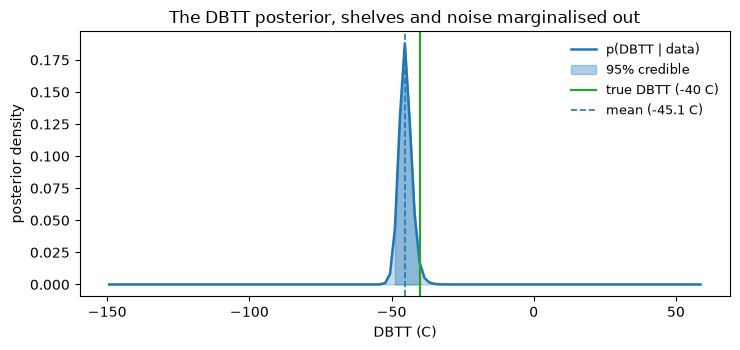

In [4]:
low, high = posterior.interval

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.fill_between(posterior.grid, posterior.density, color="C0", alpha=0.25)
ax.plot(posterior.grid, posterior.density, color="C0", lw=1.8, label="p(DBTT | data)")
inside = (posterior.grid >= low) & (posterior.grid <= high)
ax.fill_between(
    posterior.grid[inside], posterior.density[inside],
    color="C0", alpha=0.35, label=f"{posterior.credible_mass:.0%} credible",
)
ax.axvline(simulator.dbtt, color="C2", lw=1.6, label=f"true DBTT ({simulator.dbtt:g} C)")
ax.axvline(posterior.mean, color="C0", lw=1.2, ls="--", label=f"mean ({posterior.mean:.1f} C)")
ax.set_xlabel("DBTT (C)")
ax.set_ylabel("posterior density")
ax.set_title("The DBTT posterior, shelves and noise marginalised out")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### The fit behind it

The same parameters, drawn as a curve against the measurements.

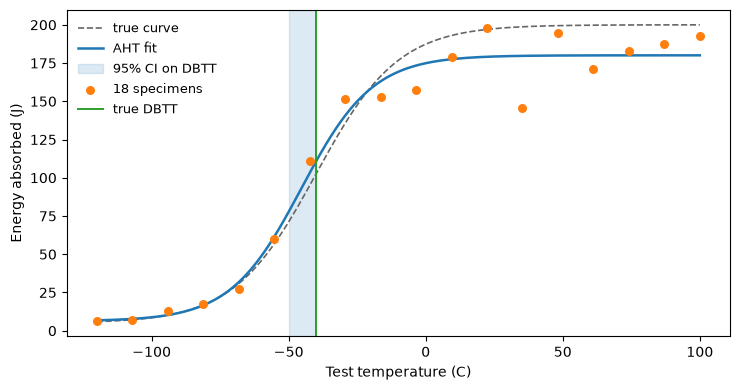

In [5]:
grid = np.linspace(*BOUNDS, 400)
a = 0.5 * (fit.shelves.lower_shelf + fit.shelves.upper_shelf)
b = 0.5 * (fit.shelves.upper_shelf - fit.shelves.lower_shelf)
aht = a + b * np.tanh((grid - fit.dbtt) / fit.width_lower)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(grid, simulator.true_curve(grid), color="0.4", lw=1.2, ls="--", label="true curve")
ax.plot(grid, aht, color="C0", lw=1.8, label="AHT fit")
ax.axvspan(low, high, color="C0", alpha=0.15, label=f"{posterior.credible_mass:.0%} CI on DBTT")
ax.scatter(t, y, s=30, color="C1", zorder=3, label=f"{len(t)} specimens")
ax.axvline(simulator.dbtt, color="C2", lw=1.4, label="true DBTT")
ax.set_xlabel("Test temperature (C)")
ax.set_ylabel("Energy absorbed (J)")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Route 2: reading it off the GP fitted on the Engine

Train a GP on the same campaign through the Engine, save its posterior across a slice as
a dataset, download it, and read the mid-shelf crossing off it.

In [6]:
PROJECT_DATASET = "dbtt_dbtt_campaign"
MODEL_NAME = "dbtt_dbtt_gp"
MEAN_NAME = "dbtt_dbtt_mean"
SD_NAME = "dbtt_dbtt_sd"

W.load_credentials("../.env")
client, project_id = W.connect()

dataset_id = W.upload_dataset(client, project_id, campaign, PROJECT_DATASET)
training = W.build_training_workflow(client, project_id, dataset_id, MODEL_NAME)
training_id = W.save_workflow(client, project_id, training, "DBTT - train model")
W.run_saved(client, project_id, training_id)

model_id = W.resource_id(client, project_id, MODEL_NAME, "model")
print(f"model resource: {model_id}")

model resource: 6ae32673bac4a9e13468f865


In [7]:
predicting = W.build_prediction_workflow(
    client, project_id, model_id, BOUNDS, MEAN_NAME, SD_NAME, num_points=201
)
predicting_id = W.save_workflow(client, project_id, predicting, "DBTT - predict slice")
curve = W.saved_prediction(client, project_id, W.run_saved(client, project_id, predicting_id))
curve.head()

,Test temperature (C),mean,sd
0,-120.0,7.125428,16.980832
1,-118.9,6.672372,16.720507
2,-117.8,6.243022,16.484207
3,-116.7,5.839743,16.271003
4,-115.6,5.464899,16.079857


In [8]:
read = dbtt_from_curve(curve[TEMPERATURE_COL], curve["mean"], curve["sd"])
print(read)
print(f"  mid-shelf level: {read.level:.1f} J   gradient there: {read.gradient:.3f} J/C")
print(f"  crossings found: {read.n_crossings}")
print(f"  true DBTT = {simulator.dbtt} C")

CurveDBTT(dbtt=-43.59 +/- 6.03)
  mid-shelf level: 98.9 J   gradient there: 2.462 J/C
  crossings found: 1
  true DBTT = -40.0 C


## Do the two agree?

They are different estimators of the same quantity — one from the measurements, one from a
model fitted to them — so they should land in the same place.

Their *spreads* are not comparable like-for-like, and the GP crossing is typically the
wider. Its vertical input is the GP's **predictive** standard deviation, which includes
the test-to-test scatter rather than just the uncertainty in the underlying curve; divide
that by a shallow transition gradient and the horizontal spread is large. The AHT
posterior, by contrast, conditions on the tanh form, and that assumption buys tightness.

In [9]:
summary = pd.DataFrame(
    [
        {
            "route": "AHT posterior (data)",
            "DBTT (C)": posterior.mean,
            "sd (C)": posterior.std,
            "low": low,
            "high": high,
        },
        {
            "route": "GP crossing (model)",
            "DBTT (C)": read.dbtt,
            "sd (C)": read.std,
            "low": read.dbtt - 1.96 * read.std,
            "high": read.dbtt + 1.96 * read.std,
        },
        {
            "route": "truth",
            "DBTT (C)": simulator.dbtt,
            "sd (C)": np.nan,
            "low": np.nan,
            "high": np.nan,
        },
    ]
)
summary.round(2)

,route,DBTT (C),sd (C),low,high
0,AHT posterior (data),-45.11,2.33,-49.93,-39.91
1,GP crossing (model),-43.59,6.03,-55.41,-31.78
2,truth,-40.00,NaN,NaN,NaN


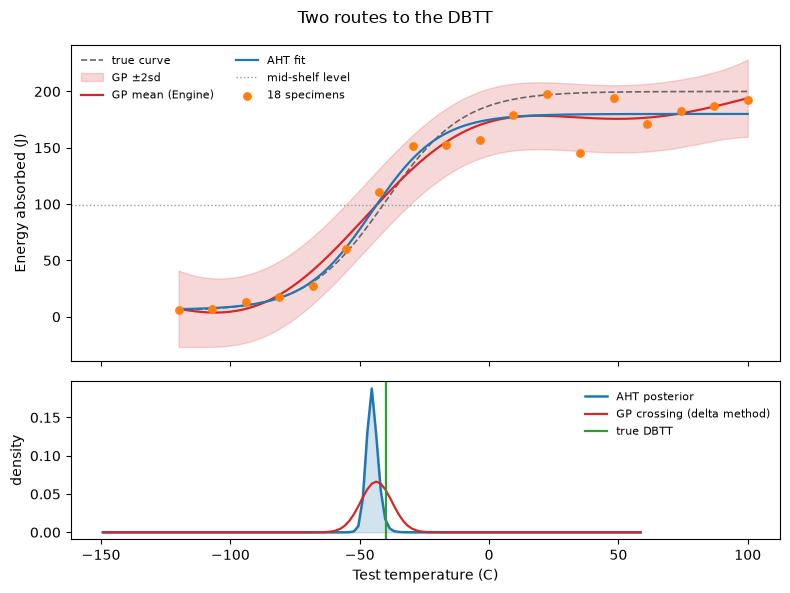

In [10]:
t_curve = curve[TEMPERATURE_COL].to_numpy()
mean_curve, sd_curve = curve["mean"].to_numpy(), curve["sd"].to_numpy()

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

top.plot(grid, simulator.true_curve(grid), color="0.4", lw=1.2, ls="--", label="true curve")
top.fill_between(
    t_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
    color="C3", alpha=0.18, label="GP ±2sd",
)
top.plot(t_curve, mean_curve, color="C3", lw=1.6, label="GP mean (Engine)")
top.plot(grid, aht, color="C0", lw=1.6, label="AHT fit")
top.axhline(read.level, color="0.6", lw=1.0, ls=":", label="mid-shelf level")
top.scatter(t, y, s=28, color="C1", zorder=3, label=f"{len(t)} specimens")
top.set_ylabel("Energy absorbed (J)")
top.legend(frameon=False, fontsize=8, ncol=2)

bottom.plot(posterior.grid, posterior.density, color="C0", lw=1.8, label="AHT posterior")
bottom.fill_between(posterior.grid, posterior.density, color="C0", alpha=0.2)
gauss = np.exp(-0.5 * ((posterior.grid - read.dbtt) / read.std) ** 2) / (
    read.std * np.sqrt(2 * np.pi)
)
bottom.plot(posterior.grid, gauss, color="C3", lw=1.6, label="GP crossing (delta method)")
bottom.axvline(simulator.dbtt, color="C2", lw=1.6, label="true DBTT")
bottom.set_xlabel("Test temperature (C)")
bottom.set_ylabel("density")
bottom.legend(frameon=False, fontsize=8)

fig.suptitle("Two routes to the DBTT", y=0.98)
fig.tight_layout()
plt.show()

## Notes

- **The posterior is the deliverable, not the point estimate.** A campaign of this size
  pins the DBTT down to a handful of degrees; quoting a single number hides that, and the
  density is visibly asymmetric.
- **Calibration is measured, not assumed.** Over 25 noise seeds the 95% credible interval
  contained the truth 24 times (96%), against 92% for the profile-likelihood interval it
  replaces.
- **The two spreads measure different things**, so do not read one as a check on the
  other. The AHT posterior is the uncertainty in the DBTT *given the tanh form*. The GP
  crossing divides a predictive standard deviation — measurement scatter included — by the
  transition gradient, which on a shallow transition makes it the wider of the two. The
  delta method also linearises at the crossing and ignores the correlation between
  neighbouring temperatures, which a draw-based estimate would capture.
- **A tight interval is not a correct one.** On this seed the AHT posterior sits a few
  degrees below the truth and its 95% interval only just contains it; the measured 96%
  coverage is across seeds, not a promise about any one campaign.
- **Only the symmetric width is supported** by `dbtt_posterior`. `compare_width_models`
  decides whether a second width is warranted at all; for this material it is not.